# Multi-Model BERT Fine-Tuning & Benchmarking on Banking77 Dataset

This notebook provides a complete benchmarking suite for fine-tuning and evaluating **12 BERT-family transformer architectures** on the **Banking77** intent classification dataset.

### Architecture-Specific Handling:
As demonstrated in the example notebook, different BERT variants require specific tokenizers, model classes, and forward-pass handling:
- **BERT Variants** (`BERT-Base`, `BERT-Large`, `SciBERT`, `BioBERT`, `PubMedBERT`, `BERT-Tiny`, `mBERT`): Uses `BertTokenizer` / `BertForSequenceClassification` with WordPiece tokenization.
- **RoBERTa** (`roberta-base`): Uses `RobertaTokenizer` / `RobertaForSequenceClassification` with Byte-Pair Encoding (BPE). Strips `token_type_ids` since RoBERTa does not use segment embeddings.
- **ALBERT** (`albert-base-v2`): Uses `AlbertTokenizer` / `AlbertForSequenceClassification` with SentencePiece tokenization, factorized embeddings, and cross-layer weight sharing.
- **DistilBERT** (`distilbert-base-uncased`): Uses `DistilBertTokenizer` / `DistilBertForSequenceClassification`. Strips `token_type_ids` since DistilBERT does not accept them in its forward pass.
- **FinBERT** (`ProsusAI/finbert`): Financial domain BERT. Uses `ignore_mismatched_sizes=True` to adapt the pre-existing 3-class sentiment head into a 77-class intent classifier.
- **DeBERTa-v3-Base** (`microsoft/deberta-v3-base`): Uses `DebertaV2Tokenizer` / `DebertaV2ForSequenceClassification` with disentangled attention and SentencePiece.

---

### Dataset Splits (Identical to LLM Fine-Tuning Benchmark):
- **Training Set**: **10,003** customer queries
- **Validation Set**: **1,000** customer queries (deterministic split from test set with seed=42)
- **Test Set**: **2,080** remaining customer queries (used identically for pre-trained baseline and post-trained evaluation)
- **Total Intent Classes**: **77** categories

---

### Automatic Output & Checkpoint Management:
- **Google Colab Mode**: Automatically detects Colab, mounts Google Drive, and saves trained models & metrics to `MyDrive/NLP-Checkpoints/BERT_training/<Model_Name>/`.
- **Local Machine Mode**: Saves trained models, tokenizers, and metrics under the current folder in `<Model_Name>/` directories.
- **Interim Checkpointing**: Saves `banking77_bert_benchmark_results.csv` after every model completes, ensuring no progress is lost.


In [1]:
# --- 1. Install Required Packages ---
!pip install -q transformers datasets scikit-learn accelerate sentencepiece protobuf tiktoken pandas matplotlib seaborn tabulate


In [2]:
# --- 2. Environment Detection & Storage Directory Setup ---
import os
import sys

def detect_environment_and_setup_storage():
    """
    Detects if running on Google Colab or Local Machine.
    - If Colab: Mounts Google Drive and sets output path to:
      MyDrive/NLP-Checkpoints/BERT_training
    - If Local: Sets output path to current working directory:
      ./ (under model name directories)
    """
    is_colab = False
    try:
        import google.colab
        is_colab = True
    except ImportError:
        is_colab = False

    if is_colab:
        print("[ENVIRONMENT] Detected Environment: GOOGLE COLAB")
        try:
            from google.colab import drive
            if not os.path.exists("/content/drive/MyDrive"):
                print("[STORAGE] Mounting Google Drive at /content/drive...")
                drive.mount("/content/drive")
            base_dir = "/content/drive/MyDrive/NLP-Checkpoints/BERT_training"
            os.makedirs(base_dir, exist_ok=True)
            print(f"[STORAGE] Checkpoints & Results will be saved to Google Drive:\n   -> {base_dir}/<Model_Name>")
            return "colab", base_dir
        except Exception as e:
            print(f"[WARNING] Could not mount Google Drive ({e}). Falling back to local ./NLP-Checkpoints/BERT_training")
            base_dir = os.path.abspath("./NLP-Checkpoints/BERT_training")
            os.makedirs(base_dir, exist_ok=True)
            return "local_fallback", base_dir
    else:
        print("[ENVIRONMENT] Detected Environment: LOCAL MACHINE")
        base_dir = os.path.abspath(".")
        print(f"[STORAGE] Checkpoints & Results will be saved under current folder:\n   -> {base_dir}/<Model_Name>")
        return "local", base_dir

ENV_TYPE, BASE_OUTPUT_DIR = detect_environment_and_setup_storage()


[ENVIRONMENT] Detected Environment: GOOGLE COLAB
[STORAGE] Mounting Google Drive at /content/drive...
Mounted at /content/drive
[STORAGE] Checkpoints & Results will be saved to Google Drive:
   -> /content/drive/MyDrive/NLP-Checkpoints/BERT_training/<Model_Name>


In [3]:
# --- 3. Import Libraries & Architecture-Specific Model Classes ---
import gc
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

import torch
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Explicit architecture-specific classes (as referenced in BERT Tuning Example notebook)
from transformers import (
    BertTokenizer, BertForSequenceClassification,
    AlbertTokenizer, AlbertForSequenceClassification,
    RobertaTokenizer, RobertaForSequenceClassification,
    DistilBertTokenizer, DistilBertForSequenceClassification,
    DebertaV2Tokenizer, DebertaV2ForSequenceClassification,
    AutoTokenizer, AutoModelForSequenceClassification,
    get_linear_schedule_with_warmup
)

# Set random seeds for reproducibility
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[HARDWARE] Using Device: {device}")
if torch.cuda.is_available():
    print(f"   GPU Model: {torch.cuda.get_device_name(0)}")
    print(f"   Total VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")


[HARDWARE] Using Device: cuda
   GPU Model: Tesla T4
   Total VRAM: 15.64 GB


In [4]:
# --- 4. Load Banking77 Dataset (Train: 10,003 | Validation: 1,000 | Test: 2,080) ---
import csv
import random
import urllib.request

BANKING77_LABELS = [
    "activate_my_card", "age_limit", "apple_pay_or_google_pay", "atm_support",
    "automatic_top_up", "balance_not_updated_after_bank_transfer",
    "balance_not_updated_after_cheque_or_cash_deposit", "beneficiary_not_allowed",
    "cancel_transfer", "card_about_to_expire", "card_acceptance", "card_arrival",
    "card_delivery_estimate", "card_linking", "card_not_working",
    "card_payment_fee_charged", "card_payment_not_recognised",
    "card_payment_wrong_exchange_rate", "card_swallowed", "cash_withdrawal_charge",
    "cash_withdrawal_not_recognised", "change_pin", "compromised_card",
    "contactless_not_working", "country_support", "declined_card_payment",
    "declined_cash_withdrawal", "declined_transfer",
    "direct_debit_payment_not_recognised", "disposable_card_limits",
    "edit_personal_details", "exchange_charge", "exchange_rate", "exchange_via_app",
    "extra_charge_on_statement", "failed_transfer", "fiat_currency_support",
    "get_disposable_virtual_card", "get_physical_card", "getting_spare_card",
    "getting_virtual_card", "lost_or_stolen_card", "lost_or_stolen_phone",
    "order_physical_card", "passcode_forgotten", "pending_card_payment",
    "pending_cash_withdrawal", "pending_top_up", "pending_transfer", "pin_blocked",
    "receiving_money", "Refund_not_showing_up", "request_refund",
    "reverted_card_payment?", "supported_cards_and_currencies", "terminate_account",
    "top_up_by_bank_transfer_charge", "top_up_by_card_charge",
    "top_up_by_cash_or_cheque", "top_up_failed", "top_up_limits", "top_up_reverted",
    "topping_up_by_card", "transaction_charged_twice", "transfer_fee_charged",
    "transfer_into_account", "transfer_not_received_by_recipient", "transfer_timing",
    "unable_to_verify_identity", "verify_my_identity", "verify_source_of_funds",
    "verify_top_up", "virtual_card_not_working", "visa_or_mastercard",
    "why_verify_identity", "wrong_amount_of_cash_received",
    "wrong_exchange_rate_for_cash_withdrawal"
]

label2id = {name: i for i, name in enumerate(BANKING77_LABELS)}
id2label = {i: name for i, name in enumerate(BANKING77_LABELS)}
num_classes = len(BANKING77_LABELS)

def load_banking77_splits():
    """
    Loads Banking77 dataset using identical splits as the LLM benchmark:
    - Train: 10,003 queries
    - Validation: 1,000 queries (deterministic split from test set with seed=42)
    - Test: 2,080 remaining queries
    Avoids deprecated dataset scripts (banking77.py).
    """
    local_candidates = ["data/banking77", "../Finetuning LLM Assignment/data/banking77"]
    for d in local_candidates:
        tr_p = os.path.join(d, "train.csv")
        va_p = os.path.join(d, "validation.csv")
        te_p = os.path.join(d, "test.csv")
        if os.path.exists(tr_p) and os.path.exists(va_p) and os.path.exists(te_p):
            print(f"[DATASET] Loading from local workspace directory ({d})...")
            def read_file(path):
                texts, labels = [], []
                with open(path, encoding="utf-8") as f:
                    for row in csv.DictReader(f):
                        texts.append(row["text"])
                        cat = row.get("category") or row.get("label")
                        labels.append(label2id[cat] if cat in label2id else int(cat))
                return texts, labels
            return read_file(tr_p) + read_file(va_p) + read_file(te_p)

    print("[DATASET] Local split files not found. Downloading raw data from PolyAI GitHub repository...")
    train_url = "https://raw.githubusercontent.com/PolyAI-LDN/task-specific-datasets/master/banking_data/train.csv"
    test_url = "https://raw.githubusercontent.com/PolyAI-LDN/task-specific-datasets/master/banking_data/test.csv"

    def fetch_csv(url):
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(req) as resp:
            lines = resp.read().decode("utf-8").splitlines()
        reader = csv.DictReader(lines)
        texts, labels = [], []
        for row in reader:
            texts.append(row["text"])
            cat = row.get("category") or row.get("label")
            labels.append(label2id[cat] if cat in label2id else int(cat))
        return texts, labels

    tr_t, tr_l = fetch_csv(train_url)
    all_te_t, all_te_l = fetch_csv(test_url)

    rng = random.Random(42)
    indices = list(range(len(all_te_t)))
    val_indices = set(rng.sample(indices, 1000))

    va_t, va_l, te_t, te_l = [], [], [], []
    for i in range(len(all_te_t)):
        if i in val_indices:
            va_t.append(all_te_t[i])
            va_l.append(all_te_l[i])
        else:
            te_t.append(all_te_t[i])
            te_l.append(all_te_l[i])

    os.makedirs("data/banking77", exist_ok=True)
    def save_split_csv(path, texts, labels):
        with open(path, "w", newline="", encoding="utf-8") as f:
            writer = csv.writer(f)
            writer.writerow(["text", "category"])
            for t, l in zip(texts, labels):
                writer.writerow([t, id2label[l]])

    save_split_csv("data/banking77/train.csv", tr_t, tr_l)
    save_split_csv("data/banking77/validation.csv", va_t, va_l)
    save_split_csv("data/banking77/test.csv", te_t, te_l)
    print("[DATASET] Cached train, validation, and test splits to data/banking77/")

    return tr_t, tr_l, va_t, va_l, te_t, te_l

train_texts, train_labels, val_texts, val_labels, test_texts, test_labels = load_banking77_splits()

print(f"[DATASET] Unified Splits Loaded Successfully:")
print(f"   Training Queries:   {len(train_texts):,}")
print(f"   Validation Queries: {len(val_texts):,} (deterministic 1,000 samples, seed=42)")
print(f"   Test Queries:       {len(test_texts):,} (evaluated identically across all models)")
print(f"   Total Classes:      {num_classes}")


[DATASET] Local split files not found. Downloading raw data from PolyAI GitHub repository...
[DATASET] Cached train, validation, and test splits to data/banking77/
[DATASET] Unified Splits Loaded Successfully:
   Training Queries:   10,003
   Validation Queries: 1,000 (deterministic 1,000 samples, seed=42)
   Test Queries:       2,080 (evaluated identically across all models)
   Total Classes:      77


In [9]:
# --- 5. Architecture-Aware Model Loader & Batch Sanitizer ---

def load_architecture_model_and_tokenizer(model_cfg, num_labels):
    """
    Architecture-specific loader handling model and tokenizer differences:
    - ALBERT: AlbertTokenizer & AlbertForSequenceClassification
    - RoBERTa: RobertaTokenizer & RobertaForSequenceClassification (no token_type_ids)
    - DistilBERT: DistilBertTokenizer & DistilBertForSequenceClassification (no token_type_ids)
    - DeBERTa-v3: DebertaV2Tokenizer & DebertaV2ForSequenceClassification
    - FinBERT: BertTokenizer & BertForSequenceClassification (reinitialized 77-class head)
    - BERT Variants (Base, Large, SciBERT, BioBERT, PubMedBERT, Tiny, mBERT):
      BertTokenizer & BertForSequenceClassification
    """
    model_id = model_cfg["model_id"]
    name = model_cfg.get("display_name", model_cfg.get("name", model_id))
    arch_type = model_cfg.get("arch_type", "bert").lower()
    tokenizer_id = model_cfg.get("tokenizer_id", model_id)

    print(f"[LOADER] Loading Architecture: '{arch_type.upper()}' for {name} ({model_id})...")

    # Resilient tokenizer instantiation:
    # 1. Try specified tokenizer_id with Fast tokenizer
    # 2. Try with use_fast=False (Slow Python tokenizer)
    # 3. For models sharing standard BERT vocabulary (like prajjwal1/bert-tiny), fall back to bert-base-uncased
    try:
        tokenizer = AutoTokenizer.from_pretrained(tokenizer_id)
    except Exception as e_fast:
        print(f"   [LOADER] Fast tokenizer loading failed for '{tokenizer_id}' ({e_fast}). Trying use_fast=False...")
        try:
            tokenizer = AutoTokenizer.from_pretrained(tokenizer_id, use_fast=False)
        except Exception as e_slow:
            print(f"   [LOADER] Slow tokenizer failed. Falling back to standard 'bert-base-uncased' fast tokenizer...")
            tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

    # Resilient model instantiation:
    # AutoModel requires 'model_type' in config.json. Legacy checkpoints (e.g., prajjwal1/bert-tiny)
    # lack this key, raising a ValueError in AutoConfig. When that happens, fall back to the
    # specific architecture class (e.g. BertForSequenceClassification) directly.
    try:
        model = AutoModelForSequenceClassification.from_pretrained(
            model_id,
            num_labels=num_labels,
            ignore_mismatched_sizes=True
        )
    except Exception as e_model:
        print(f"   [LOADER] AutoModel loading failed ({e_model}). Falling back to architecture-specific class for '{arch_type}'...")
        if arch_type == "bert":
            model = BertForSequenceClassification.from_pretrained(
                model_id,
                num_labels=num_labels,
                ignore_mismatched_sizes=True
            )
        elif arch_type == "roberta":
            model = RobertaForSequenceClassification.from_pretrained(
                model_id,
                num_labels=num_labels,
                ignore_mismatched_sizes=True
            )
        elif arch_type == "albert":
            model = AlbertForSequenceClassification.from_pretrained(
                model_id,
                num_labels=num_labels,
                ignore_mismatched_sizes=True
            )
        elif arch_type == "distilbert":
            model = DistilBertForSequenceClassification.from_pretrained(
                model_id,
                num_labels=num_labels,
                ignore_mismatched_sizes=True
            )
        elif "deberta" in arch_type:
            model = DebertaV2ForSequenceClassification.from_pretrained(
                model_id,
                num_labels=num_labels,
                ignore_mismatched_sizes=True
            )
        else:
            raise e_model

    # Ensure model.config has model_type defined for downstream batch sanitization
    if not hasattr(model.config, "model_type") or not model.config.model_type:
        model.config.model_type = arch_type

    print(f"   -> Resolved Tokenizer Class: {tokenizer.__class__.__name__}")
    print(f"   -> Resolved Model Class:     {model.__class__.__name__}")
    if "finbert" in model_id.lower():
        print(f"   -> Special Handling: Successfully re-initialized FinBERT's 3-class classifier into a 77-class intent head.")

    return tokenizer, model


def sanitize_batch_for_model(batch, model, device):
    """
    Special Input Handling:
    - RoBERTa and DistilBERT models DO NOT accept 'token_type_ids' in their forward pass.
      Passing 'token_type_ids' to Roberta or DistilBERT causes a TypeError.
    - BERT and ALBERT DO accept 'token_type_ids'.
    This function dynamically strips unsupported input arguments and places tensors on device.
    """
    model_type = getattr(model.config, "model_type", "").lower()
    clean_batch = {}

    for key, val in batch.items():
        if key == "token_type_ids" and ("roberta" in model_type or "distilbert" in model_type):
            continue
        clean_batch[key] = val.to(device)

    return clean_batch


class BankingDataset(Dataset):
    """PyTorch Dataset for Banking77 tokenized encodings."""
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __getitem__(self, idx):
        item = {key: val[idx] for key, val in self.encodings.items()}
        item["labels"] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item

    def __len__(self):
        return len(self.labels)


In [6]:
# --- 6. Unified Evaluation Function ---
def evaluate_model(model, dataloader, device, desc="Evaluating"):
    """
    Evaluates a model on a DataLoader and computes:
    - Accuracy
    - Precision (Weighted & Macro)
    - Recall (Weighted & Macro)
    - F1-Score (Weighted)
    - Macro F1-Score
    """
    model.eval()
    all_preds = []
    all_targets = []
    total_eval_loss = 0.0

    with torch.no_grad():
        for batch in tqdm(dataloader, desc=desc, leave=False):
            batch_inputs = sanitize_batch_for_model(batch, model, device)
            outputs = model(**batch_inputs)

            if outputs.loss is not None:
                total_eval_loss += outputs.loss.item()

            logits = outputs.logits
            preds = torch.argmax(logits, dim=-1).cpu().numpy()
            targets = batch["labels"].numpy()

            all_preds.extend(preds)
            all_targets.extend(targets)

    avg_loss = total_eval_loss / max(1, len(dataloader))

    acc = accuracy_score(all_targets, all_preds)
    p_weighted = precision_score(all_targets, all_preds, average="weighted", zero_division=0)
    p_macro = precision_score(all_targets, all_preds, average="macro", zero_division=0)
    r_weighted = recall_score(all_targets, all_preds, average="weighted", zero_division=0)
    r_macro = recall_score(all_targets, all_preds, average="macro", zero_division=0)
    f1_weighted = f1_score(all_targets, all_preds, average="weighted", zero_division=0)
    f1_macro = f1_score(all_targets, all_preds, average="macro", zero_division=0)

    metrics = {
        "loss": avg_loss,
        "accuracy": acc,
        "precision_weighted": p_weighted,
        "precision_macro": p_macro,
        "recall_weighted": r_weighted,
        "recall_macro": r_macro,
        "f1_weighted": f1_weighted,
        "f1_macro": f1_macro
    }
    return metrics


In [10]:
# --- 7. Model Configurations Registry ---
MODELS_CONFIG = [
    {
        "name": "BERT-Base",
        "save_dir_name": "BERT-Base",
        "model_id": "bert-base-uncased",
        "arch_type": "bert",
        "batch_size": 32,
        "grad_accum": 1,
        "lr": 3e-5,
    },
    {
        "name": "DistilBERT",
        "save_dir_name": "DistilBERT",
        "model_id": "distilbert-base-uncased",
        "arch_type": "distilbert",
        "batch_size": 32,
        "grad_accum": 1,
        "lr": 3e-5,
    },
    {
        "name": "SciBERT",
        "save_dir_name": "SciBERT",
        "model_id": "allenai/scibert_scivocab_uncased",
        "arch_type": "bert",
        "batch_size": 32,
        "grad_accum": 1,
        "lr": 3e-5,
    },
    {
        "name": "BioBERT",
        "save_dir_name": "BioBERT",
        "model_id": "dmis-lab/biobert-v1.1",
        "arch_type": "bert",
        "batch_size": 32,
        "grad_accum": 1,
        "lr": 3e-5,
    },
    {
        "name": "PubMedBERT",
        "save_dir_name": "PubMedBERT",
        "model_id": "microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract",
        "arch_type": "bert",
        "batch_size": 32,
        "grad_accum": 1,
        "lr": 3e-5,
    },
    {
        "name": "BERT-Tiny",
        "save_dir_name": "BERT-Tiny",
        "model_id": "prajjwal1/bert-tiny",
        "tokenizer_id": "bert-base-uncased",
        "arch_type": "bert",
        "batch_size": 64,
        "grad_accum": 1,
        "lr": 5e-5,
    },
    {
        "name": "mBERT",
        "save_dir_name": "mBERT",
        "model_id": "bert-base-multilingual-cased",
        "arch_type": "bert",
        "batch_size": 32,
        "grad_accum": 1,
        "lr": 3e-5,
    },
    {
        "name": "BERT-Large",
        "save_dir_name": "BERT-Large",
        "model_id": "bert-large-uncased",
        "arch_type": "bert",
        "batch_size": 16,
        "grad_accum": 2,
        "lr": 1.5e-5,
    },
    {
        "name": "RoBERTa",
        "save_dir_name": "RoBERTa",
        "model_id": "roberta-base",
        "arch_type": "roberta",
        "batch_size": 32,
        "grad_accum": 1,
        "lr": 2e-5,
    },
    {
        "name": "ALBERT",
        "save_dir_name": "ALBERT",
        "model_id": "albert-base-v2",
        "arch_type": "albert",
        "batch_size": 32,
        "grad_accum": 1,
        "lr": 2e-5,
    },
    {
        "name": "FinBERT",
        "save_dir_name": "FinBERT",
        "model_id": "ProsusAI/finbert",
        "arch_type": "bert",
        "batch_size": 32,
        "grad_accum": 1,
        "lr": 2e-5,
    },
    {
        "name": "DeBERTa-v3-Base",
        "save_dir_name": "DeBERTa-v3-Base",
        "model_id": "microsoft/deberta-v3-base",
        "arch_type": "deberta-v2",
        "batch_size": 16,
        "grad_accum": 2,
        "lr": 2e-5,
    }
]

# Hyperparameters
EPOCHS = 3
MAX_SEQ_LENGTH = 64
WARMUP_RATIO = 0.1
WEIGHT_DECAY = 0.01
MAX_GRAD_NORM = 1.0

SAMPLE_QUERIES = [
    "I lost my card abroad, how do I freeze it immediately?",
    "Why was I charged an extra fee for an international transfer?",
    "How long does it take for a deposited cheque to clear?",
    "Can you help me increase my daily ATM cash withdrawal limit?",
    "I see a payment on my statement that I did not authorize."
]

MODELS_TO_RUN = MODELS_CONFIG
print(f"Registered {len(MODELS_CONFIG)} models. Configured to run {len(MODELS_TO_RUN)} models.")


Registered 12 models. Configured to run 12 models.


In [11]:
# --- 8. Master Benchmark Loop: Pre-Eval -> Train -> Post-Eval -> Save ---
results_records = []
output_csv_path = os.path.join(BASE_OUTPUT_DIR, "banking77_bert_benchmark_results.csv")

for model_idx, cfg in enumerate(MODELS_TO_RUN, 1):
    model_name = cfg["name"]
    save_dir_name = cfg["save_dir_name"]
    model_id = cfg["model_id"]
    batch_size = cfg["batch_size"]
    grad_accum = cfg["grad_accum"]
    lr = cfg["lr"]

    model_output_dir = os.path.join(BASE_OUTPUT_DIR, save_dir_name)
    os.makedirs(model_output_dir, exist_ok=True)

    # Check if this model was already completed in an earlier run
    metrics_file = os.path.join(model_output_dir, "metrics.json")
    if os.path.exists(metrics_file):
        print("=" * 80)
        print(f"[{model_idx}/{len(MODELS_TO_RUN)}] CACHED: {model_name} ({model_id})")
        print(f"   Already completed at: {model_output_dir}")
        print("   Skipping re-training and loading existing metrics into benchmark summary...")
        print("=" * 80)
        try:
            with open(metrics_file, "r") as f:
                saved_summary = json.load(f)
            pre_m = saved_summary["pre_metrics"]
            post_m = saved_summary["post_metrics"]
            deltas = saved_summary.get("deltas", {})
            record = {
                "Model Name": model_name,
                "Model ID": model_id,
                "Save Directory": model_output_dir,
                "Pre-Train Accuracy (%)": round(pre_m["accuracy"] * 100, 2),
                "Post-Train Accuracy (%)": round(post_m["accuracy"] * 100, 2),
                "Accuracy Gain (%)": deltas.get("accuracy_gain_pct", round((post_m["accuracy"] - pre_m["accuracy"]) * 100, 2)),
                "Pre-Train Macro F1 (%)": round(pre_m["f1_macro"] * 100, 2),
                "Post-Train Macro F1 (%)": round(post_m["f1_macro"] * 100, 2),
                "Macro F1 Gain (%)": deltas.get("macro_f1_gain_pct", round((post_m["f1_macro"] - pre_m["f1_macro"]) * 100, 2)),
                "Post-Train Weighted F1 (%)": round(post_m["f1_weighted"] * 100, 2),
                "Post-Train Macro Precision (%)": round(post_m["precision_macro"] * 100, 2),
                "Post-Train Weighted Precision (%)": round(post_m["precision_weighted"] * 100, 2),
                "Post-Train Macro Recall (%)": round(post_m["recall_macro"] * 100, 2),
                "Post-Train Weighted Recall (%)": round(post_m["recall_weighted"] * 100, 2),
                "Training Time (Mins)": saved_summary.get("training_time_minutes", 0.0),
                "Epochs": saved_summary.get("epochs", EPOCHS),
            }
            results_records.append(record)
            continue
        except Exception as e:
            print(f"   [WARNING] Could not read existing metrics ({e}). Re-training model...")

    print("=" * 80)
    print(f"[{model_idx}/{len(MODELS_TO_RUN)}] BENCHMARKING: {model_name} ({model_id})")
    print(f"   Save Directory: {model_output_dir}")
    print(f"   Batch: {batch_size} | Grad Accum: {grad_accum} | LR: {lr} | Epochs: {EPOCHS}")
    print("=" * 80)

    # 1. Architecture-Specific Tokenizer and Model Loading
    tokenizer, model = load_architecture_model_and_tokenizer(cfg, num_classes)
    model.to(device)

    # 2. Tokenize Datasets with the Model's Specific Tokenizer (Train=10,003, Val=1,000, Test=2,080)
    print(f"[DATA] Tokenizing Banking77 splits with {tokenizer.__class__.__name__} (max_length={MAX_SEQ_LENGTH})...")
    train_encodings = tokenizer(train_texts, padding=True, truncation=True, max_length=MAX_SEQ_LENGTH, return_tensors="pt")
    val_encodings = tokenizer(val_texts, padding=True, truncation=True, max_length=MAX_SEQ_LENGTH, return_tensors="pt")
    test_encodings = tokenizer(test_texts, padding=True, truncation=True, max_length=MAX_SEQ_LENGTH, return_tensors="pt")

    train_dataset = BankingDataset(train_encodings, train_labels)
    val_dataset = BankingDataset(val_encodings, val_labels)
    test_dataset = BankingDataset(test_encodings, test_labels)

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

    # ---------------------------------------------------------
    # 3. PRE-TRAINED EVALUATION (Baseline on 2,080 Test Queries)
    # ---------------------------------------------------------
    print(f"[EVAL] Running PRE-TRAINED Baseline Evaluation on Test Set (2,080 queries)...")
    pre_metrics = evaluate_model(model, test_loader, device, desc=f"Pre-Eval ({model_name})")

    print(f"   [Pre-Trained] Test Accuracy:    {pre_metrics['accuracy'] * 100:.2f}%")
    print(f"   [Pre-Trained] Test Macro F1:    {pre_metrics['f1_macro'] * 100:.2f}%")
    print(f"   [Pre-Trained] Test Weighted F1: {pre_metrics['f1_weighted'] * 100:.2f}%")

    # ---------------------------------------------------------
    # 4. FINE-TUNING LOOP (with Validation Set Tracking)
    # ---------------------------------------------------------
    print(f"\n[TRAINING] Starting Fine-Tuning for {EPOCHS} Epochs on 10,003 Training Queries...")
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)
    total_training_steps = (len(train_loader) // grad_accum) * EPOCHS
    scheduler = get_linear_schedule_with_warmup(
        optimizer,
        num_warmup_steps=int(total_training_steps * WARMUP_RATIO),
        num_training_steps=total_training_steps
    )

    start_train_time = time.time()

    for epoch in range(EPOCHS):
        model.train()
        total_epoch_loss = 0.0
        optimizer.zero_grad()

        pbar = tqdm(enumerate(train_loader), total=len(train_loader), desc=f"Epoch {epoch+1}/{EPOCHS} [{model_name}]")
        for step, batch in pbar:
            batch_inputs = sanitize_batch_for_model(batch, model, device)
            outputs = model(**batch_inputs)
            loss = outputs.loss / grad_accum
            loss.backward()

            total_epoch_loss += loss.item() * grad_accum

            if (step + 1) % grad_accum == 0 or (step + 1) == len(train_loader):
                torch.nn.utils.clip_grad_norm_(model.parameters(), MAX_GRAD_NORM)
                optimizer.step()
                scheduler.step()
                optimizer.zero_grad()

            pbar.set_postfix({"loss": f"{total_epoch_loss / (step + 1):.4f}"})

        avg_loss = total_epoch_loss / len(train_loader)

        # Validation tracking on the 1,000 validation queries
        val_metrics = evaluate_model(model, val_loader, device, desc=f"Val-Epoch-{epoch+1}")
        print(f"   Epoch {epoch+1}/{EPOCHS} | Train Loss: {avg_loss:.4f} | Val Acc: {val_metrics['accuracy']*100:.2f}% | Val Macro F1: {val_metrics['f1_macro']*100:.2f}%")

    train_duration = time.time() - start_train_time
    print(f"[COMPLETE] Fine-Tuning Complete in {train_duration / 60:.2f} minutes.")

    # ---------------------------------------------------------
    # 5. POST-TRAINED EVALUATION (On 2,080 Test Queries)
    # ---------------------------------------------------------
    print(f"\n[EVAL] Running POST-TRAINED Benchmark Evaluation on Test Set (2,080 queries)...")
    post_metrics = evaluate_model(model, test_loader, device, desc=f"Post-Eval ({model_name})")

    print(f"   [Post-Trained] Test Accuracy:           {post_metrics['accuracy'] * 100:.2f}% (Gain: +{(post_metrics['accuracy'] - pre_metrics['accuracy']) * 100:.2f}%)")
    print(f"   [Post-Trained] Test Macro Precision:    {post_metrics['precision_macro'] * 100:.2f}%")
    print(f"   [Post-Trained] Test Weighted Precision: {post_metrics['precision_weighted'] * 100:.2f}%")
    print(f"   [Post-Trained] Test Macro Recall:       {post_metrics['recall_macro'] * 100:.2f}%")
    print(f"   [Post-Trained] Test Weighted Recall:    {post_metrics['recall_weighted'] * 100:.2f}%")
    print(f"   [Post-Trained] Test Macro F1:           {post_metrics['f1_macro'] * 100:.2f}% (Gain: +{(post_metrics['f1_macro'] - pre_metrics['f1_macro']) * 100:.2f}%)")
    print(f"   [Post-Trained] Test Weighted F1:        {post_metrics['f1_weighted'] * 100:.2f}%")

    # ---------------------------------------------------------
    # 6. QUALITATIVE PREDICTION EXAMPLES
    # ---------------------------------------------------------
    print(f"\n[INFERENCE] Prediction Examples with Fine-Tuned {model_name}:")
    model.eval()
    sample_inputs = tokenizer(SAMPLE_QUERIES, padding=True, truncation=True, max_length=MAX_SEQ_LENGTH, return_tensors="pt")
    sample_inputs = sanitize_batch_for_model(sample_inputs, model, device)

    with torch.no_grad():
        sample_logits = model(**sample_inputs).logits
        sample_probs = torch.softmax(sample_logits, dim=-1)
        top_probs, top_preds = torch.topk(sample_probs, k=1, dim=-1)

    for q, pred_id, prob in zip(SAMPLE_QUERIES, top_preds.squeeze(-1).tolist(), top_probs.squeeze(-1).tolist()):
        print(f'   Query: "{q}"')
        print(f"   -> Predicted Intent: **{id2label[pred_id]}** (Confidence: {prob*100:.2f}%)")

    # ---------------------------------------------------------
    # 7. SAVE TRAINED MODEL & METRICS TO DESTINATION DIRECTORY
    # ---------------------------------------------------------
    print(f"\n[STORAGE] Saving Fine-Tuned Model & Tokenizer to:\n   -> {model_output_dir}")
    model.save_pretrained(model_output_dir)
    tokenizer.save_pretrained(model_output_dir)

    model_eval_summary = {
        "model_name": model_name,
        "model_id": model_id,
        "epochs": EPOCHS,
        "training_time_minutes": round(train_duration / 60, 2),
        "dataset_split": {
            "train_samples": len(train_texts),
            "val_samples": len(val_texts),
            "test_samples": len(test_texts)
        },
        "pre_metrics": {k: float(v) for k, v in pre_metrics.items()},
        "post_metrics": {k: float(v) for k, v in post_metrics.items()},
        "deltas": {
            "accuracy_gain_pct": round((post_metrics["accuracy"] - pre_metrics["accuracy"]) * 100, 2),
            "macro_f1_gain_pct": round((post_metrics["f1_macro"] - pre_metrics["f1_macro"]) * 100, 2),
        }
    }
    with open(os.path.join(model_output_dir, "metrics.json"), "w") as f:
        json.dump(model_eval_summary, f, indent=2)

    # ---------------------------------------------------------
    # 8. RECORD PERFORMANCE METRICS FOR GLOBAL BENCHMARK TABLE
    # ---------------------------------------------------------
    record = {
        "Model Name": model_name,
        "Model ID": model_id,
        "Save Directory": model_output_dir,
        "Pre-Train Accuracy (%)": round(pre_metrics["accuracy"] * 100, 2),
        "Post-Train Accuracy (%)": round(post_metrics["accuracy"] * 100, 2),
        "Accuracy Gain (%)": round((post_metrics["accuracy"] - pre_metrics["accuracy"]) * 100, 2),
        "Pre-Train Macro F1 (%)": round(pre_metrics["f1_macro"] * 100, 2),
        "Post-Train Macro F1 (%)": round(post_metrics["f1_macro"] * 100, 2),
        "Macro F1 Gain (%)": round((post_metrics["f1_macro"] - pre_metrics["f1_macro"]) * 100, 2),
        "Post-Train Weighted F1 (%)": round(post_metrics["f1_weighted"] * 100, 2),
        "Post-Train Macro Precision (%)": round(post_metrics["precision_macro"] * 100, 2),
        "Post-Train Weighted Precision (%)": round(post_metrics["precision_weighted"] * 100, 2),
        "Post-Train Macro Recall (%)": round(post_metrics["recall_macro"] * 100, 2),
        "Post-Train Weighted Recall (%)": round(post_metrics["recall_weighted"] * 100, 2),
        "Training Time (min)": round(train_duration / 60, 2)
    }
    results_records.append(record)

    # Save checkpoint CSV after each model
    df_interim = pd.DataFrame(results_records)
    df_interim.to_csv(output_csv_path, index=False)
    print(f"[CHECKPOINT] Updated global benchmark CSV: {output_csv_path}")

    # ---------------------------------------------------------
    # 9. GPU MEMORY CLEANUP
    # ---------------------------------------------------------
    del model, optimizer, scheduler, train_loader, val_loader, test_loader
    del train_dataset, val_dataset, test_dataset
    del train_encodings, val_encodings, test_encodings, tokenizer
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    print(f"[CLEANUP] Cleaned up GPU memory after {model_name}\n")

print("ALL MODEL BENCHMARKS COMPLETED!")


[1/12] CACHED: BERT-Base (bert-base-uncased)
   Already completed at: /content/drive/MyDrive/NLP-Checkpoints/BERT_training/BERT-Base
   Skipping re-training and loading existing metrics into benchmark summary...
[2/12] CACHED: DistilBERT (distilbert-base-uncased)
   Already completed at: /content/drive/MyDrive/NLP-Checkpoints/BERT_training/DistilBERT
   Skipping re-training and loading existing metrics into benchmark summary...
[3/12] CACHED: SciBERT (allenai/scibert_scivocab_uncased)
   Already completed at: /content/drive/MyDrive/NLP-Checkpoints/BERT_training/SciBERT
   Skipping re-training and loading existing metrics into benchmark summary...
[4/12] CACHED: BioBERT (dmis-lab/biobert-v1.1)
   Already completed at: /content/drive/MyDrive/NLP-Checkpoints/BERT_training/BioBERT
   Skipping re-training and loading existing metrics into benchmark summary...
[5/12] CACHED: PubMedBERT (microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract)
   Already completed at: /content/drive/MyDrive/NLP-

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 17.8MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: prajjwal1/bert-tiny
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were 

   -> Resolved Tokenizer Class: BertTokenizer
   -> Resolved Model Class:     BertForSequenceClassification
[DATA] Tokenizing Banking77 splits with BertTokenizer (max_length=64)...


... (163 outputs left out)

Post-Eval (DeBERTa-v3-Base):   0%|          | 0/130 [00:00<?, ?it/s]

   [Post-Trained] Test Accuracy:           1.39% (Gain: +-0.14%)
   [Post-Trained] Test Macro Precision:    0.02%
   [Post-Trained] Test Weighted Precision: 0.02%
   [Post-Trained] Test Macro Recall:       1.30%
   [Post-Trained] Test Weighted Recall:    1.39%
   [Post-Trained] Test Macro F1:           0.04% (Gain: +-0.00%)
   [Post-Trained] Test Weighted F1:        0.04%

[INFERENCE] Prediction Examples with Fine-Tuned DeBERTa-v3-Base:
   Query: "I lost my card abroad, how do I freeze it immediately?"
   -> Predicted Intent: **activate_my_card** (Confidence: nan%)
   Query: "Why was I charged an extra fee for an international transfer?"
   -> Predicted Intent: **activate_my_card** (Confidence: nan%)
   Query: "How long does it take for a deposited cheque to clear?"
   -> Predicted Intent: **activate_my_card** (Confidence: nan%)
   Query: "Can you help me increase my daily ATM cash withdrawal limit?"
   -> Predicted Intent: **activate_my_card** (Confidence: nan%)
   Query: "I see a pay

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[CHECKPOINT] Updated global benchmark CSV: /content/drive/MyDrive/NLP-Checkpoints/BERT_training/banking77_bert_benchmark_results.csv
[CLEANUP] Cleaned up GPU memory after DeBERTa-v3-Base

ALL MODEL BENCHMARKS COMPLETED!



FINAL BANKING77 BENCHMARK SUMMARY TABLE (Evaluated on 2,080 Test Queries)
| Model Name      |   Pre-Train Accuracy (%) |   Post-Train Accuracy (%) |   Accuracy Gain (%) |   Pre-Train Macro F1 (%) |   Post-Train Macro F1 (%) |   Post-Train Weighted F1 (%) |   Post-Train Macro Precision (%) |   Post-Train Macro Recall (%) |   Training Time (min) |
|:----------------|-------------------------:|--------------------------:|--------------------:|-------------------------:|--------------------------:|-----------------------------:|---------------------------------:|------------------------------:|----------------------:|
| BERT-Base       |                     1.25 |                     87.07 |               85.82 |                     0.06 |                     85.73 |                        85.98 |                            87.68 |                         86.96 |                nan    |
| DistilBERT      |                     1.39 |                     85.43 |               84.04 |       

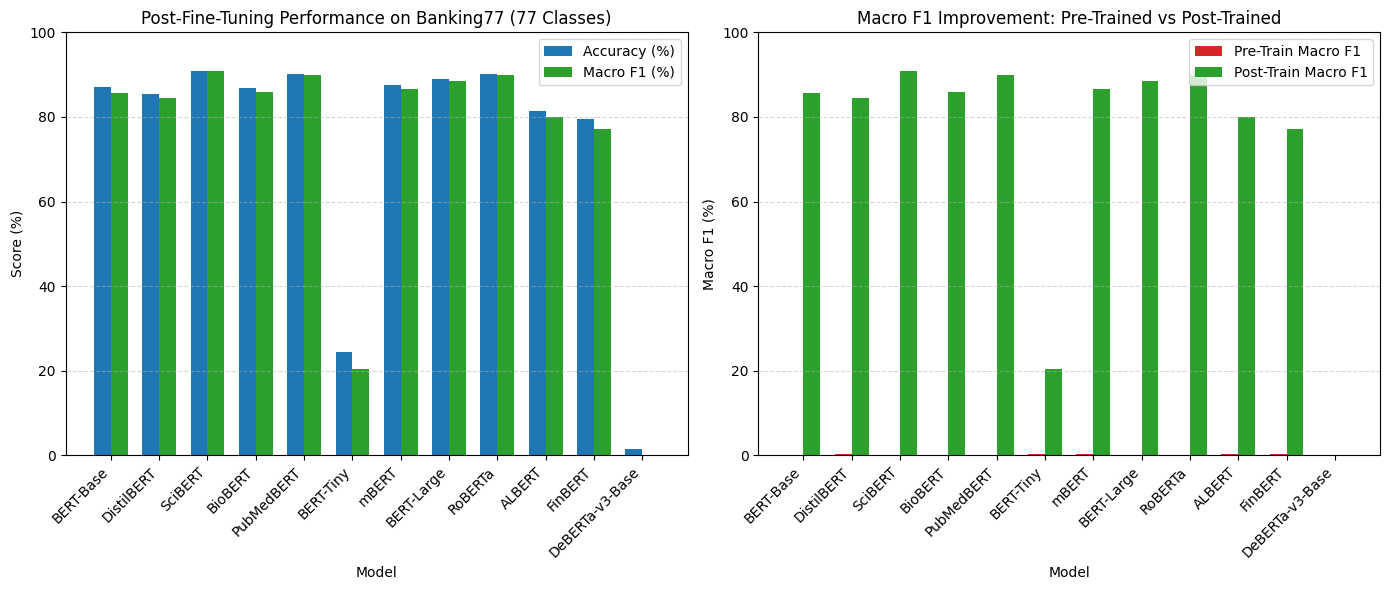

[VISUALIZATION] Saved comparison visualization to: /content/drive/MyDrive/NLP-Checkpoints/BERT_training/banking77_bert_comparison.png


In [12]:
# --- 9. Comprehensive Comparison Table & Visualizations ---
benchmark_df = pd.DataFrame(results_records)
print("\n" + "=" * 90)
print("FINAL BANKING77 BENCHMARK SUMMARY TABLE (Evaluated on 2,080 Test Queries)")
print("=" * 90)
display_cols = [
    "Model Name",
    "Pre-Train Accuracy (%)",
    "Post-Train Accuracy (%)",
    "Accuracy Gain (%)",
    "Pre-Train Macro F1 (%)",
    "Post-Train Macro F1 (%)",
    "Post-Train Weighted F1 (%)",
    "Post-Train Macro Precision (%)",
    "Post-Train Macro Recall (%)",
    "Training Time (min)"
]
print(benchmark_df[display_cols].to_markdown(index=False) if hasattr(benchmark_df, "to_markdown") else benchmark_df[display_cols])

# Plotting Comparison Charts
plot_save_path = os.path.join(BASE_OUTPUT_DIR, "banking77_bert_comparison.png")
plt.figure(figsize=(14, 6))

# Plot 1: Post-Trained Accuracy vs Macro F1
plt.subplot(1, 2, 1)
x = np.arange(len(benchmark_df))
width = 0.35
plt.bar(x - width/2, benchmark_df["Post-Train Accuracy (%)"], width, label="Accuracy (%)", color="#1f77b4")
plt.bar(x + width/2, benchmark_df["Post-Train Macro F1 (%)"], width, label="Macro F1 (%)", color="#2ca02c")
plt.xlabel("Model")
plt.ylabel("Score (%)")
plt.title("Post-Fine-Tuning Performance on Banking77 (77 Classes)")
plt.xticks(x, benchmark_df["Model Name"], rotation=45, ha="right")
plt.ylim(0, 100)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Plot 2: Pre-Trained vs Post-Trained Macro F1 Gain
plt.subplot(1, 2, 2)
plt.bar(x - width/2, benchmark_df["Pre-Train Macro F1 (%)"], width, label="Pre-Train Macro F1", color="#d62728")
plt.bar(x + width/2, benchmark_df["Post-Train Macro F1 (%)"], width, label="Post-Train Macro F1", color="#2ca02c")
plt.xlabel("Model")
plt.ylabel("Macro F1 (%)")
plt.title("Macro F1 Improvement: Pre-Trained vs Post-Trained")
plt.xticks(x, benchmark_df["Model Name"], rotation=45, ha="right")
plt.ylim(0, 100)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig(plot_save_path, dpi=300)
plt.show()
print(f"[VISUALIZATION] Saved comparison visualization to: {plot_save_path}")


In [13]:
# --- 10. Interactive Prediction Function ---
def load_and_predict(query, model_save_name, top_k=3):
    """
    Loads a saved fine-tuned model checkpoint from its directory and predicts intent.
    """
    model_dir = os.path.join(BASE_OUTPUT_DIR, model_save_name)
    if not os.path.exists(model_dir):
        print(f"[ERROR] Model directory '{model_dir}' not found. Please train the model first.")
        return

    print(f"[LOADING] Loading fine-tuned checkpoint from: {model_dir}...")
    saved_tokenizer = AutoTokenizer.from_pretrained(model_dir)
    saved_model = AutoModelForSequenceClassification.from_pretrained(model_dir).to(device)
    saved_model.eval()

    inputs = saved_tokenizer(query, return_tensors="pt", truncation=True, max_length=MAX_SEQ_LENGTH, padding=True)
    inputs = sanitize_batch_for_model(inputs, saved_model, device)

    with torch.no_grad():
        outputs = saved_model(**inputs)
        probs = torch.softmax(outputs.logits, dim=-1).squeeze(0)
        top_probs, top_indices = torch.topk(probs, k=top_k)

    print(f'\nInput Query: "{query}"')
    print(f"Top {top_k} Predicted Intents:")
    for rank, (idx, prob) in enumerate(zip(top_indices.tolist(), top_probs.tolist()), 1):
        print(f"   {rank}. {id2label[idx]:<35} (Confidence: {prob*100:.2f}%)")

    del saved_model, saved_tokenizer
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# Example usage:
# load_and_predict("Can I transfer money directly using Apple Pay?", "FinBERT")
